In [2]:
import random
import numpy as np
import string
import matplotlib.pyplot as plt

# Exploring the Birthday Paradox and Hash Collisions: A Theoretical and Experimental Study

## Introduction
    The main idea behind this project is to explain how certain mathematical concepts in the field of probability and combinatorics can be applied to understand vulnerability issues in cybersecurity. A very good example of an information security problem of major importance is when collision happens in hash functions in case preventative measures are not taken. One of these measures can be choosing secure hash functions which can be implemented as working solusion. Hashing algorithm called SHA-256 is still considered to be safe to use due to the current computing hardware limitation. 
    if we get back to the issue with the collsions related to the hash functions, one of the cases with what could go wrong is when data is transfered through a computer network. If a secure hash algorithm is used then this ensures that a file which has been transfered from one computer to another computer through a computer network remains the same. In other words, the data integrity is preserved. Hash functions are widely used beyond network security. Common applications include password storage, hash tables, file integrity checks, blockchain technology, and digital signatures. Definately, the main purpose of this project is not to explore all the possible ways in which hashing functions can be implemented. It will rather be a concentrated efford combined with a smooth transition meaning gradually building up knowledge toward exploration of the subject topic(Cotton, 2023).

## Event- based probability
    	First of all we need to clarify to ourselves that probability lives between 0 and 1 meaning consequently 0 percent and 100 percent. Let’s consider the following event-based probability example. If we roll a six-sided die, there is a 1/6 probability of getting 6 as a result. Another case study could be flipping a coin. The chances of getting tails is 1/2(Thomas, 2022). When we think about how probabiliy could be described then we might introduce two terms: a numerator and a denominator. The first definition is designating the number of ways an event could happen and the second one is designating all possible ways something could occur. The formula is as it follows:

$$\text{Probability} = \frac{\text{Numerator}}{\text{Denominator}}$$

## NOT a complement

    We already learnt one of the ways how to calculate the probability of something happening. We could also think of the chances of an event not occurring. Then this is called NOT a complement(Webb, 2026). According to its definition, if two events are complementary then we can find the probability one of the events to happen if you subtract the other from 1. Of course it is necessary for one of the occurrences to be known in order to work out the other. It can be said that the probability of something to happen arithmetically combined with the probability of its complement is equal to 1. This can be expressed with the following formula:
$$P(A) + P(\overline{A}) = 1 \quad \text{or} \quad P(A) = 1 - P(\overline{A}) \quad \text{or} \quad P(\overline{A}) = 1 - P(A)$$

    The benefit of using the complement rule is to skip multiple steps required for multiple calculations which has enormous gains when calculating two complementary events. If we return to the six-sided die, it can be concluded that the probability not to have 6 as a result when rolling it, is equal to 1 - 1/6 or 5/6. In real life, sometimes it is easier to find the solution of what is the likelihood of a particular event not occurring in order to figure out when anything is just about to happen. Acting in this way preventative measures can be taken.

## Birthday Paradox
    Our initial intuition might lead us into wrong conclusions. For example, in case we go to a room full with people then we could wonder how many individuals it is necessary to be available at the premise just to have at least one birthday match between two people. Someone might incorrectly say that the minimum number of folks must be at least around one hundred and eighty which is approximately the half of three hundred and sixty five. Actually, the reality differs from that(Kozyrkov, 2019). 
	If we choose just 23 people there is a little bit more than 50 percent probability two of these people to have the same birthday. This is called the birthday paradox or the birthday problem. When we take a closer look at it, we will figure out that the first person out of 23 people will have 22 comparisons. The second has already compared himself with the first one and will have 21 comparisons to make and so on and so forth. We could potentially conclude that all possible combinations or comparisons are equal to the sum of (22 + 21 + 20 + … + 1) which is 253. In other words the same result could be accomplished if we perform the following calculation:
$$\frac{n(n-1)}{2} =  23 \times \frac{22}{2}$$

	When calculating the probability of shared birthdays, it is important to also consider the complementary probability — that no one shares a birthday.
    We assume that a person’s birthday can fall on any of 365 days (excluding 29 February). Therefore, the probability that two people do not share a birthday is:
$$P(\text{not matching}) = \frac{364}{365} \approx 99.726027\%$$

	In a group of 23 people there are 253 possible pairs. The probability that none of these pairs share a birthday is:

$$\left(\frac{364}{365}\right)^{253} \approx 49.952\%$$

    After calculating the probability that no one in a group of 23 people shares a birthday, we can apply the complement rule to find the probability that at least two people share a birthday:  
$$P(\text{at least one shared birthday}) = 1 - 0.49952 \approx 0.50048 \quad (50.05\%)$$

    Keeping the probability just above 50% is useful because it helps us identify the threshold at which a shared birthday becomes more likely than not.

## The Birthday Paradox represented by showing Python simulations 
    In each of the following seven Python code cells we are going to run 10 000 Pyhton simulations to group of imaginary people with different sizes. Each member of these groups will be assigned with arbitrary number representing the possible random dates of birth in one year starting from 1 to 365 including. By running the experiment 10 000 times, we are supposed to get better estimated matching probability. The main suggestion is that the probability of 23 people having at least one match is slightly above 50 percent. The code does not count all the available birthday matches in each group but it rather checks whether there is at least one shared birthday. The experiment will be run multiple times in order to figure out how the probability of two people having the same date of birth grows when the number of imaginary group of people increases. The second suggestion is that the likelihood of having a match when 50 people are put in a room grows beyond 90 percent.

In [3]:
def shared_birthday(group_size: int) -> bool:
    #Returns True if at least two people who have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 20, num_trials = 10000)
print(f"Estimated probability with 20 people: {probability:.4f}")

Estimated probability with 20 people: 0.4019


In [4]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people who have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 23, num_trials = 10000)
print(f"Estimated probability with 23 people: {probability:.4f}")

Estimated probability with 23 people: 0.5059


In [5]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 30, num_trials = 10000)
print(f"Estimated probability with 30 people: {probability:.4f}")

Estimated probability with 30 people: 0.7080


In [6]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 40, num_trials = 10000)
print(f"Estimated probability with 40 people: {probability:.4f}")

Estimated probability with 40 people: 0.8915


In [7]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 50, num_trials = 10000)
print(f"Estimated probability with 50 people: {probability:.4f}")

Estimated probability with 50 people: 0.9713


In [8]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 60, num_trials = 10000)
print(f"Estimated probability with 60 people: {probability:.4f}")

Estimated probability with 60 people: 0.9932


In [9]:
def shared_birthday(group_size: int) -> bool:
    #Return True if at least two people have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

#Runing the experiment
probability = simulate_birthday_paradox(group_size = 70, num_trials = 10000)
print(f"Estimated probability with 70 people: {probability:.4f}")

Estimated probability with 70 people: 0.9995


## Reviewing the results
    After running the experiment multiple times with the following groups of people- 20, 23, 30, 40, 50, 60, and 70, it can be said that 23 people in a room are enough to get at least one birthday match. The probability this to happen is slightly above 50%. It is quite interesting that group of 20 people decrease the probability of matching with roughly 10 percent but just 30 people in a room increase the probability to around 70% . What is even more intriguing is that only 50 people in one premise could raise the likelihood of at least one match to approximately 96%. If the number of indivisuals is equal to 70 or more then the probability of at least one match is almost 100%. The following graph represents this.

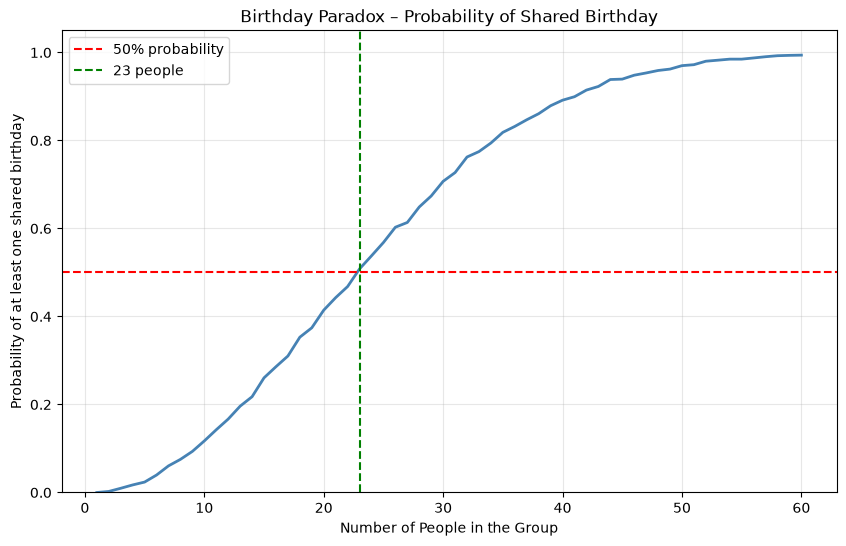

In [10]:
#Creating the data for the plot
group_sizes = list(range(1, 61))  # from 1 to 60 people
probabilities = [simulate_birthday_paradox(size) for size in group_sizes]

#The final graph
plt.figure(figsize = (10, 6))
plt.plot(group_sizes, probabilities, color = 'steelblue', linewidth = 2)
plt.axhline(y = 0.5, color = 'red', linestyle = '--', label = '50% probability')
plt.axvline(x = 23, color = 'green', linestyle = '--', label = '23 people')
plt.title('Birthday Paradox – Probability of Shared Birthday')
plt.xlabel('Number of People in the Group')
plt.ylabel('Probability of at least one shared birthday')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.ylim(0, 1.05)
plt.show()

In the graph above the blue curve represents how the probability grows as the group gets larger. The red dashed line is showing the 50% probability and and green dashed line shows the 23 people mark.